In [2]:
# Libs
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import HTML
from matplotlib.animation import FuncAnimation

# Procura o utils.py subindo pela árvore de diretórios
repo_root = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(repo_root))

from utils import LinearRegression, MSE, GradientDescent, OLS

# Importar os dados
df = pd.read_csv(r'../../aulas/datasets/NHANES-2017-2018-height-weight.csv')
df.drop(columns=['Unnamed: 0'], inplace=True)


*Este notebook é uma Cola e não é uma amostra do estado final da Aula01.ipynb, mas contém as bases tanto para a Aula01.ipynb quanto o material as funções da aula.*    
*Lembrando que o notebook é uma versão resumida criada para complementar a aula, ou seja, ele sozinho pdoe ser insuficiente.*

# Bloco 1 - Introdução a Ciência de Dados e a Limpeza de Dados

## Apresentação

*(Introdução ao Curso, incluindo a ementa, abordagem matemática, etc.)*  
Parte matemática introduzir assim:  

A Ciência de Dados como disciplina teórica requer uma matemática de nível de graduação, principalmente para as disciplinas da Álgebra Linear e Estatística para a manipulação dos dados e dos modelos, e noções de Cálculo para o entendimento de como os modelos 'aprendem' e são treinados. No entanto, neste curso, decidimos simplificar ao máximo as bases matemáticas dos modelos mas sem anular completamente a matemática, tão presente no dia a dia do cientista. Assim, fica implícito, e e muitos casos apenas como referência auxiliar, a matemática mais formal que baseia a área, e espera-se do aluno que deseja seguir na área estude essas áreas, ou siga as dicas recomendadas no material de `proximos-passos.md`.

## O que é Ciência de Dados?

A Ciência de Dados é uma área situada na interseção entre 3 diferentes áreas ou ramos do conhecimento: a Matemática, a Metodologia Científica, e a Programação. De modo geral, o Cientista de Dados se preocupa em trabalhar com dados e informações na finalidade de transformar esses dados em ações cabíveis de serem tomadas, frequentemente envolvendo criação de *modelos preditivos* e *modelos de Inteligência Artificial* pensados em tentar prever o futuro com base no passado.

Ou seja, o Cientista de Dados ajuda na tomada de decisão ao fornecer as ferramentas e as análises necessárias não apenas para *compreender os dados* e *entender o que eles significam* contextualizados, mas também é capaz de *criar algoritmos e métodos que atuam sobre os dados* para prever valores, classificar clientes, estipular riscos, recomendar produtos, entre várias outras. Todas as tarefas abaixo descritas são, por exemplo, cabíveis de serem uma tarefa para um cientista de dados:

- Criar dashboards capazes de traduzir informações do passado e do presente de forma inteligente e dinâmica;
- Costruir um modelo que ajuda a estipular o faturamento da empresa ao longo do tempo;
- Classificar e segmentar clientes entre perfis de risco e de compra, para adotar políticas específicas para cada grupo de cliente;
- Criar um algoritmo capaz de recomendar os melhores produtos dado o perfil do cliente;
- Criar um algoritmo que automaticamente extrair informações de imagens enviadas;
- Computa a potencial mudança nos cliques que uma eventual decisão de design no site podem trazer;

entre outros.

### Analista de Dados ou Cientista de Dados?
Muito se confunde sobre quais são de fato as responsabilidades de um *Cientista de Dados* em constraste com a de um *Analista de Dados*. Esta distinção é ainda mais borrada pelo fato de que muitas empresas não distinguem as duas áreas como separadas. Mas, via de regra, o Cientista de dados é um *Analista de Dados especializado*, com formação mais ampla e adequada para a construção de modelos de aprendizado de máquina e tratamento estatístico mais rigoroso. Além disso, o Cientista de Dados frequentemente está lidando com problemas relacionados *ao futuro*, como planejamento de vendas e previsão de risco, enquanto os analistas de dados costumam focar no passado e presente dos dados.

Existem vários tipos diferentes de aprendizado de máquina e modelos preditivos, muitos dos quais possuem toda uma área de estudo e de especialização apenas para eles. Durante este curso, entretanto, abordaremos principalmente dois tipos de problemas resolvíveis com modelos de aprendizado de máquina: **Regressão* e *Classificação*.
Problemas de *Regressão* estão associados com a previsão de um valor *numérico contínuo*, como por exemplo, prever o preço de um produto a partir de uma série de características. Já problemas de *Classificação* envolvem categorizar os dados em dois ou mais grupos distintos, frequentemente chamados de classes, como criar um modelo que separa clients de alto risco e de baixo risco.

Neste curso, aprendermeos tanto a criar um modelo de regressão, usando *Regressão Linear*, quanto um modelo de classificação, usando *Regressão Logística*.

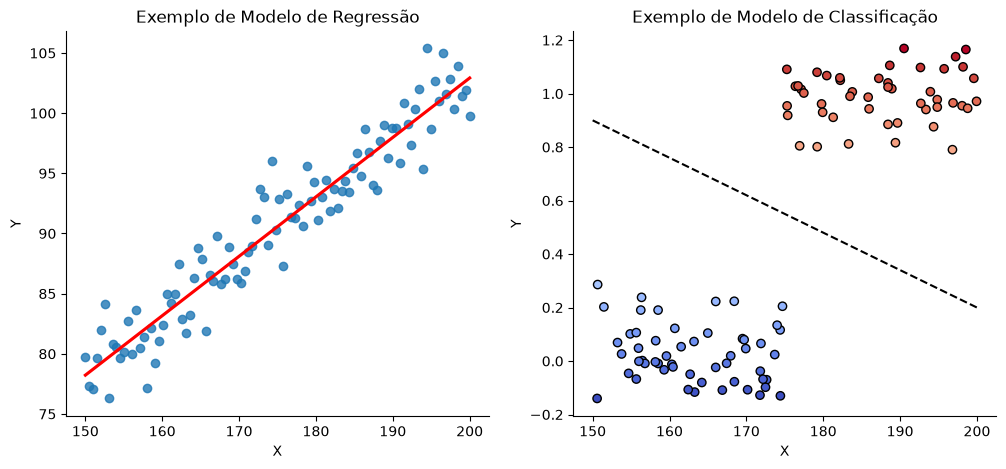

In [3]:
# Exemplo de modelos de ML ilustrativos

# Criar dados de exemplo para regressão linear e SVM
reg_x = np.linspace(150, 200, 100).reshape(-1, 1)
reg_y = 0.5 * reg_x + 3 + np.random.normal(0, 2, size=reg_x.shape)
svm_x = np.random.uniform(150, 200, size=(100, 1))
svm_y = (svm_x > 175).astype(int).ravel() + np.random.normal(0, 0.1, size=svm_x.shape[0])

plt.subplots(1, 2, figsize=(12, 5))

# Gráfico de regressão linear
plt.subplot(1, 2, 1)
sns.regplot(x=reg_x.ravel(), y=reg_y.ravel(), ci=None, line_kws={"color": "red"})
plt.title('Exemplo de Modelo de Regressão')
plt.xlabel('X')
plt.ylabel('Y')
sns.despine()

# Gráfico de SVM
plt.subplot(1, 2, 2)
plt.scatter(svm_x, svm_y, c=svm_y, cmap='coolwarm', edgecolor='k')
sns.lineplot(x=[150, 200], y=[0.9, 0.2], color='black', linestyle='--')
plt.title('Exemplo de Modelo de Classificação')
plt.xlabel('X')
plt.ylabel('Y')
sns.despine()


# O que é linearidade?
Para estudarmos os próximos modelos, é fundamental conhecermos o conceito de linearidade. Esse é um conceito estudado na disciplina de álgebra linear que não será aprofundada neste curso, mas, podemos ter um princípio de uma noção mais intuitiva analisando um exemplo em específico no gráfico abaixo. Observe que o gráfico não tem título e nem eixo Y: isso é *proposital*, pois esse gráfico na verdade é um *recorte* de um gráfico maior. Logo entenderemos por que fizemos esse corte.

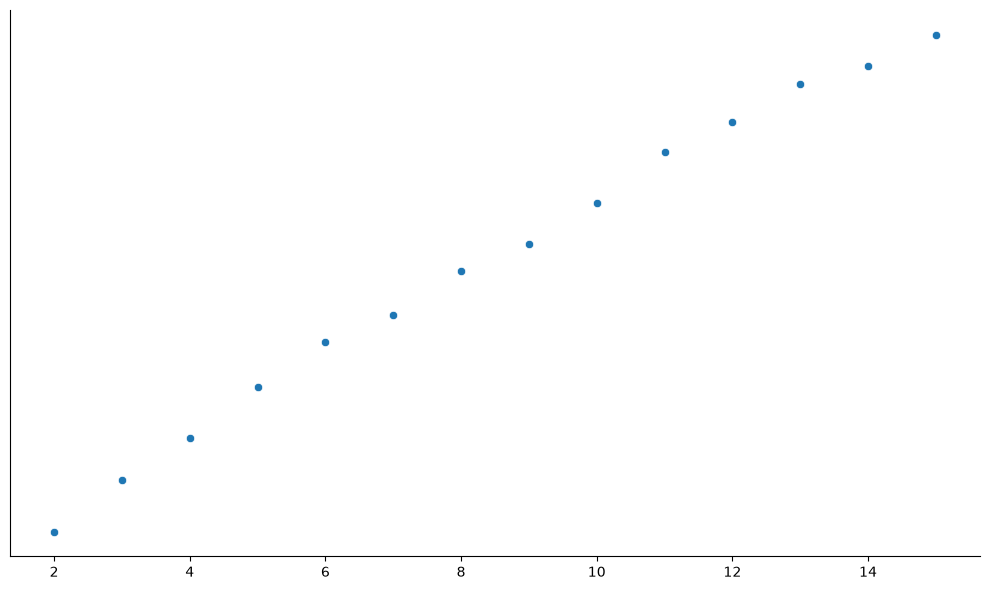

In [4]:
# Criar dados medianos
mediana_altura = df.groupby('age')['height'].median()

# Gráfico da mediana de altura apenas com X <= 15

plt.figure(figsize=(10, 6))
sns.scatterplot(x=mediana_altura[mediana_altura.index <= 15].index, y=mediana_altura[mediana_altura.index <= 15].values, marker='o')

# Esconder nome do titulo e dos eixos x e y
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Esconder labels dos eixos
plt.yticks([])

sns.despine()
plt.tight_layout()
plt.show()

Pelo menos para o período cortado do gráfico (cortado até $x = 15$), que não necessariamente representa toda a distribuição, parece claro deduzir que esta distribuição pode ser representada por uma *linha reta* ou *relação linear* entre os dados, já que claramente existe uma tendência de que, a medida em que se aumenta o x, aumenta-se o y. Podemos associar a esta relação uma *reta* que relaciona valores de X para respectivos valores de Y.

Os detalhes em como essa reta pode ser criada ficarão para os próximos tópicos: por enquanto, vamos apenas considerar que nós traçamos uma reta quaisquer representando esse crescimento linear nos dados em Y com relação ao X.

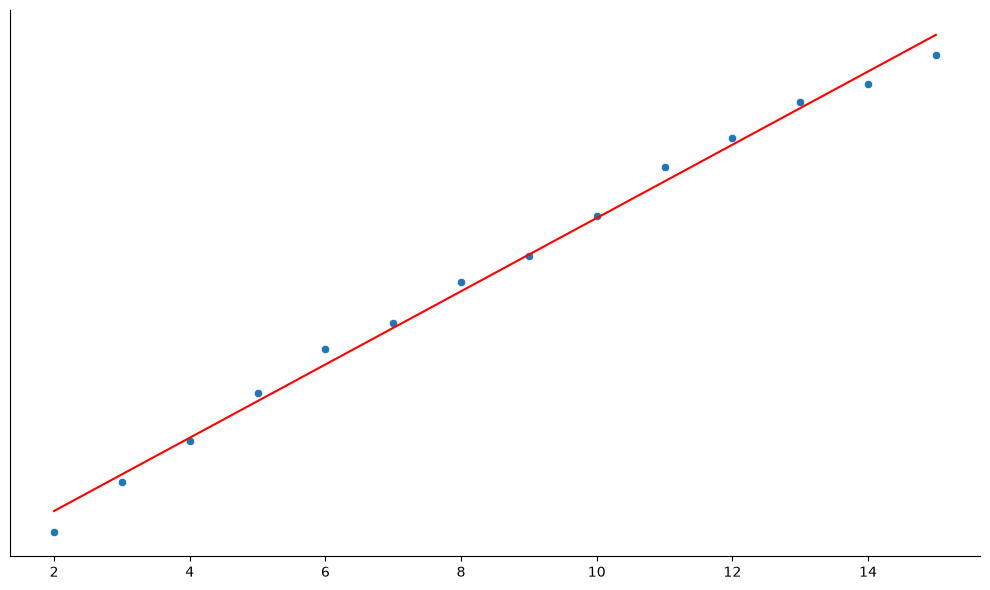

In [5]:
# Criar uma regressão linear ols APENAS para os dados X <= 15 e plotar a reta

x = mediana_altura[mediana_altura.index <= 15].index.values.reshape(-1, 1) # reshape para transformar em array 2D
y = mediana_altura[mediana_altura.index <= 15].values.reshape(-1, 1)

model = LinearRegression()
ols = OLS()
model = ols.fit(model, x, y)
y_pred = model.predict(x)

# Plotar a reta
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker='o')
plt.plot(x, y_pred, color='red')

# Esconder nome do titulo e dos eixos x e y
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Esconder labels dos eixos
plt.yticks([])

sns.despine()
plt.tight_layout()
plt.show()

Perceba que, agora que nós determinamos explicitamente uma *relação linear* entre Y em X, nós poderíamos usar de um artifício de "extrapolar a reta": ver quais valores de Y obteríamos a medida que os valores de X aumentam ainda mais acima de 15, como se estivéssemos projetando a reta para frente. Deixando os detalhes de como essa reta foi criada de lado momentamente, podemos observar algo interessante quando avaliamos o valor de y quando $x = 80$:

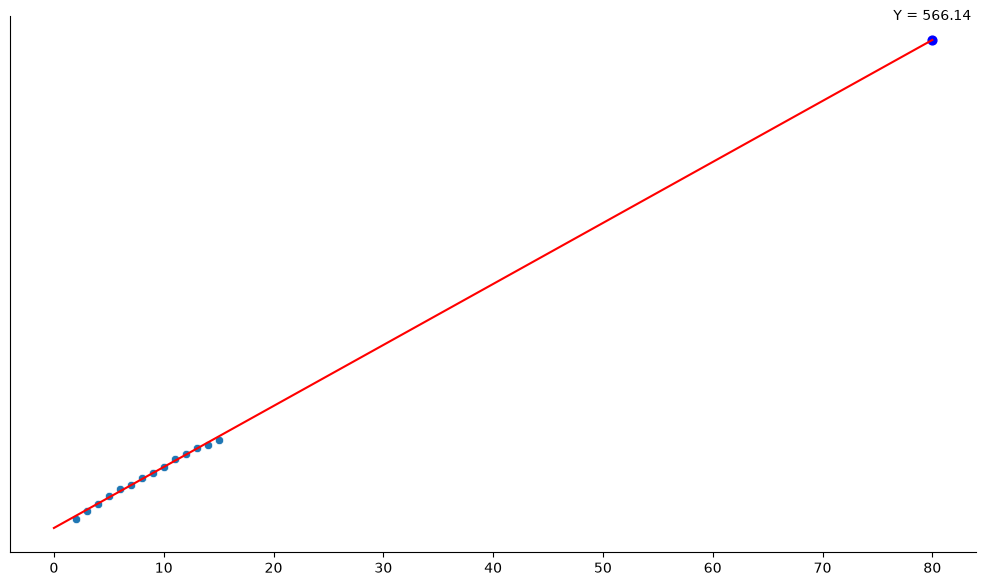

In [6]:
# Plotar gráfico extrapolado até o X = 80, usando a reta da regressão OLS treinada apenas com os dados X <= 15

x_estrapolado = np.arange(0, 81).reshape(-1, 1)
y_estrapolado = model.predict(x_estrapolado)
y_80 = model.predict(np.array([[80]]))
y_80_valor = y_80.item()

# Plotar a reta extrapolada
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker="o")
plt.plot(x_estrapolado.flatten(), y_estrapolado.flatten(), color="red")

# Exibir o ponto X = 80
plt.scatter(80, y_80_valor, color="blue", s=40, label=f"Y(80) = {y_80_valor:.2f}")

# Texto acima do ponto
plt.annotate(f"Y = {y_80_valor:.2f}", xy=(80, y_80_valor), xytext=(0, 12), textcoords="offset points", ha="center", va="bottom")

plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.yticks([])
sns.despine()
plt.tight_layout()
plt.show()

Ou seja, quando extrapolamos a reta e a utilizamos para prever valores *maiores* que $x = 15$, mesmo que ainda não estejamos exibindo os dados de Y para esses valores de X (lembre-se, o gráfico está com uma quantidade de dados específica, uma parte da distribuição total, por motivos que já serão esclarecidos), nós conseguimos *prever* ou *inferir* valores de Y correspondentes. Isso voltará a ser pertinente no próximo tópico sobre Regressão Linear, onde aprenderemos não apenas o que de fato essa reta representa, mas também como criar a melhor reta possível.

Mas primeiro, lembrando que o dataset não contém o conjunto completo dos dados, vamos revelar os verdadeiros nomes dos eixos nas distribuições originais e vermos se nossa interpretação inicial faz algum sentido.

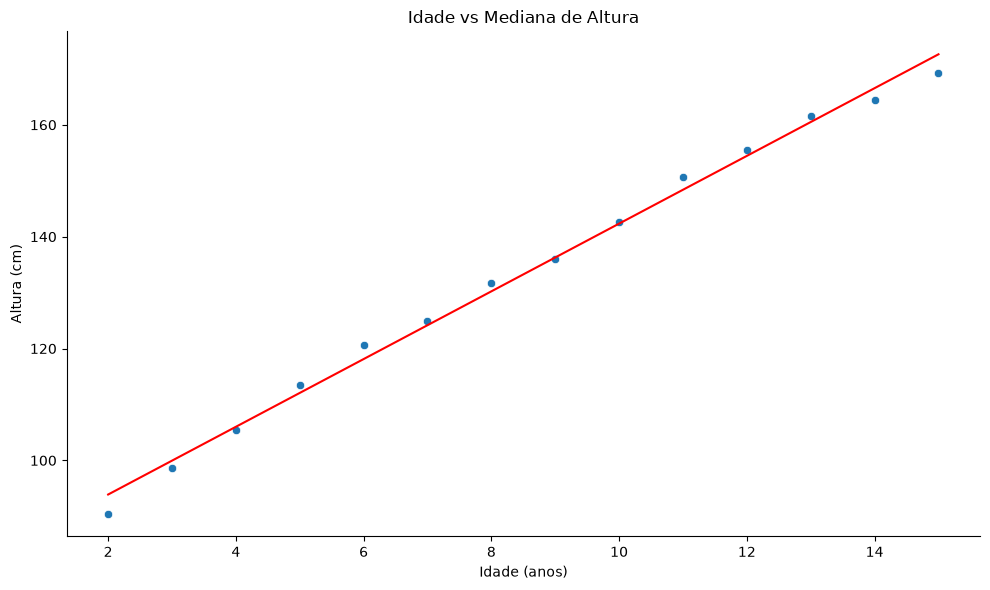

In [7]:
# Mesmo gráfico, mas com nome nos eixos

# Plotar a reta
plt.figure(figsize=(10, 6))
sns.scatterplot(x=x.flatten(), y=y.flatten(), marker='o')
plt.plot(x, y_pred, color='red')

# Esconder nome do titulo e dos eixos x e y
plt.title('Idade vs Mediana de Altura')
plt.xlabel('Idade (anos)')
plt.ylabel('Altura (cm)')

sns.despine()
plt.tight_layout()
plt.show()

Agora com os eixos revelados, faz sentido ainda pensar que a relação entre idade e altura é linear? Isto é, faz sentido a ideia de que, a medida em que a idade aumenta, aumenta-se cada vez mais a altura?
Isso parece longe da verdade. De fato, ao exibirmos a verdadeira distribuição dos dados em comparação com a reta que criamos:

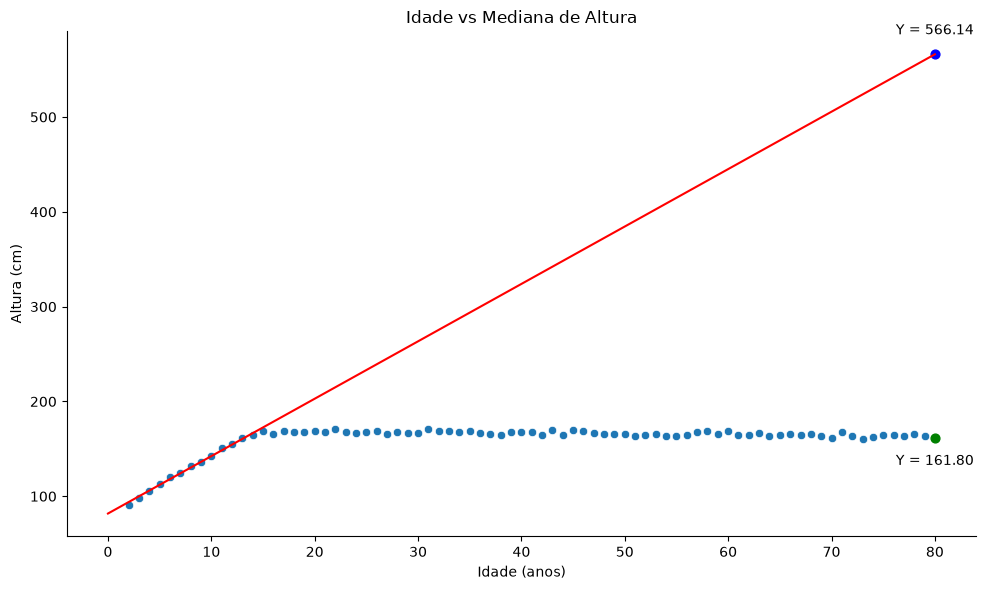

In [8]:
# Gráfico completo com a reta prevista para X <= 15.
y_80 = mediana_altura[mediana_altura.index == 80].item()

plt.figure(figsize=(10, 6))
sns.scatterplot(x=mediana_altura.index, y=mediana_altura.values, marker='o')
sns.lineplot(x=x_estrapolado.flatten(), y=y_estrapolado.flatten(), color='red')
plt.scatter(80, y_80_valor, color="blue", s=40, label=f"Y(80) = {y_80_valor:.2f}")
plt.annotate(f"Y = {y_80_valor:.2f}", xy=(80, y_80_valor), xytext=(0, 12), textcoords="offset points", ha="center", va="bottom")
plt.scatter(80, y_80, color="green", s=40, label=f"Y(80) = {y_80:.2f}")
plt.annotate(f"Y = {y_80:.2f}", xy=(80, y_80), xytext=(0, -12), textcoords="offset points", ha="center", va="top")

plt.xlabel('Idade (anos)')
plt.ylabel('Altura (cm)')

sns.despine()
plt.title('Idade vs Mediana de Altura')
plt.tight_layout()
plt.show()

Podemos ver que nossa previsão errou significantemente quando consideramos apenas o conjunto inicial dos dados, atribuindo um valor de Y = 566, ou *5 metros de altura*, para pessoas com idade próxima a 80. Isto obviamente não pode ser correto, e o gráfico mostra um claro padrão na mediana das idades a partir de X = 15-18, onde as pessoas **param de crescer** e portanto, a relação linear que surge nos primeiros pontos de y em relação a X não se mantém válida para os demais pontos de X. 

Este é um bom exemplo de uma relação **não-linear**, isto é, a relação entre X (idade) e Y (altura) não pôde ser facilmente expressão por meio de uma relação linear entre suas variáveis. A relação até pode ser descrita como linear até valores próximos de $x = 18$, quando rapidamente a taxa de crescimento diminui e se estabiliza, tornando a distribuição inteira um exemplo de uma distribuição não linear.

 Descobrir primeiro um exemplo de uma relação não-linear pode ser útil para entender os limites do que modelos de aprendizado de máquina lineares, como o que veremos em seguida, podem possuir. 

# Regressão Linear
A Regressão Linear é um modelo de Aprendizado de Máquina, e portanto, se propõe a *prever* valores de Y de saída com base em valores X de entrada, por meio de uma *função linear* entre as variáveis. Intuitivamente, o modelo de Regressão Linear pode ser entendido como uma tentativa de *encaixar uma reta que melhor representa o conjunto dos dados*. Essa noção intuitiva, porém, pode ser incompleta em casos onde há mais de uma variável de entrada (isto é , mais de um "x"). Para fins deste curso, focaremos no entendimento na **Single Linear Regression**, ou Regressão Linear Singular, com apenas uma variável de entrada e uma variável de saída, mas um estudo mais aprofundado na álgebra linear dará as ferramentas necessárias para entender a regressão múltipla.

No Ensino Médio, aprende-se que uma reta pode ser representada no plano da seguinte forma:

$$\boxed{y = ax +b}$$

com $a$ sendo chamado de *coeficiente angular*, responsável pela inclinação da reta,  
e *b* sendo chamado de intercepto, onde a reta cruza com o eixo y.  

Experimente substituir os valores de $a$ e de $b$ no código abaixo para ver a mudança no gráfico.

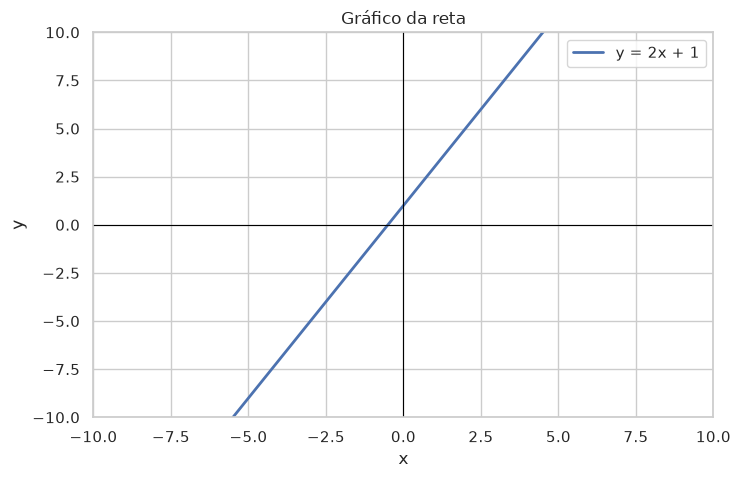

In [9]:
a = 2   # Coeficiente angular (inclinação)
b = 1   # Intercepto (onde a reta cruza o eixo y)

x = np.linspace(-10, 10, 200)
y = a * x + b

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
plt.plot(x, y, label=f"y = {a}x + {b}", linewidth=2)

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

# Limites fixos dos eixos
plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Gráfico da reta")
plt.legend()
plt.show()

Assim sendo, se temos uma distribuição com valores de X e de Y, e queremos criar uma reta que melhor os represente, podemos modelar isso como:

$\hat{y} = ax + b$, onde $\hat{y}$ representa o valor previsto por nosso modelo (o que nosso modelo devolve para *aquela* entrada específica de x).  
Se *x* representa os valores que nós temos como "entrada" e $\hat{y}$ o valor previsto pelo modelo, isso significa que os únicos parâmetros que podemos 'mexer' são as variáveis $a$ e $b$. Ou seja, queremos encontrar quais $a$ e $b$ são os mais *eficazes* para representar os dados.

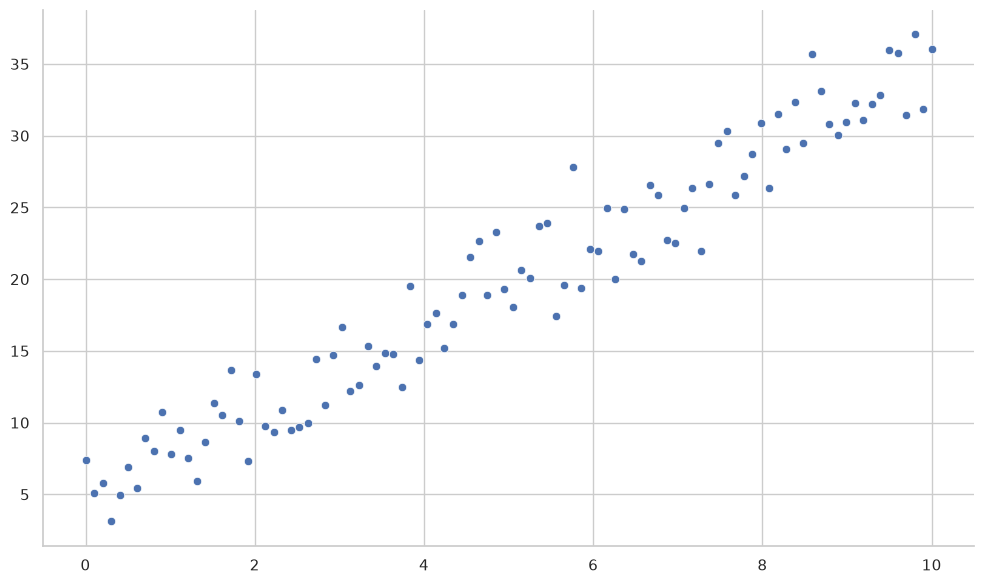

In [10]:
# Gerar dados lineares com ruído gaussiano para representar uma certa relação linear arbitrária

x = np.linspace(0, 10, 100)
y = 3 * x + 5 + np.random.normal(0, 2, size=x.shape)  # y = 3x + 5 + ruído gaussiano

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, marker='o')
sns.despine()
plt.tight_layout()
plt.show()

Para definirmos o que significa realmente uma "melhor" reta, precisamos de um *parâmetro*, que nos permita diferenciar diferentes possíveis retas. 

## Apresentando a Função de Custo - Erro Médio Quadrático

O que significa, matematicamente, "melhor"? Para que um computador possa buscar a *melhor* reta, precisamos transformar essa ideia intuitiva em um **número**, que nos diga quão boa (ou quão ruim) é uma determinada reta. Para isso, utilizamos uma **Função de Custo**.
Intuitivamente, uma Função de Custo é uma função matemática que irá *quantificar o erro do modelo*, isto é, vai dizer o quão mal o modelo performa se comparado com a verdadeira natureza da distribuição. Com essa função de custo em mãos, podemos montar um algoritmo ou procedimento que tenta ao máximo *ajustar o modelo para minimizar os erros*, até chegar em um ponto onde o modelo está satisfatório.

Existem diferentes funções de custo, com diferentes motivações por trás. Algumas são melhores para certos tipos de modelo, e outras possuem interpretações diferentes que podem se adequar melhor em casos específicos. Contudo, de longe o modelo mais utilizado é o **Erro Médio Quadrático**, ou **MSE (Mean Squared Error)**. Ele possui a seguinte fórmula.

$$\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

$n$ : número de features (linhas)  
$\sum_{i=1}^{n}$ : soma do i-ésimo elemento = 1 até n  
$\hat{y}$ : predição do modelo


A notação pode assustar, mas é realmente mais simples do que parece. O Erro Médio Quadrático estará medindo **o quanto o modelo erra, em média**. Perceba primeiro o termo $(y_i - \hat{y})$: essa é simplesmente a diferença entre o valor que o **modelo preveu** do valor real dos dados, isto é, representa o **erro** do nosso modelo, por se assim dizer.  
Nós **elevamos esse erro ao quadrado**, depois **somamos todos os erros quadráticos**, e **dividimos pela quantidade de linhas**, obtendo por fima uma **média dos erros quadráticos**.

### Por que elevar ao quadrado?
Uma questão válida que pode ter surgido é por que, ao pegarmos a diferença entre o valor previsto pelo modelo e o valor real do modelo, nós elevamos esse erro ao quadrado. Na verdade, isso é feito por 3 motivos principais:

1. **Manter os valores positivos**: todo número real elevado ao quadrado se transforma em número positivo. Isso é relevante para nós, pois sem essa transformação, teríamos **erros positivos** e **erros negativos** se cancelando. Por exemplo, se para um certo X nosso modelo errou em *-10* (errou -10 unidades, errou 'pra baixo'), e pra um outro X errou *+10* (errou 10 unidades, errou 'pra cima'), esses dois erros de cancelariam na soma e pareceria que o modelo não errou nada para esses dois X, quando na verdade, o modelo errou duas 20 unidades no total.
2. **Penaliza erros altos**: a função quadrática é não-linear e fazer com que números grandes ficam significantemente maiores ao se elevarem ao quadrado do que ficariam em uma simples relação linear, fazendo com que erros mais graves sejam penalizados em relação a uma reta com potencialmente erros menos graves em magnitude.
3. **Suaviza a função de erro**: Um conceito mais avançado de Cálculo, mas elevar ao quadrado torna a função de custo significantemente mais fácil de ser calculada por algoritmos devido a ser uma função derivável em todo o ponto.

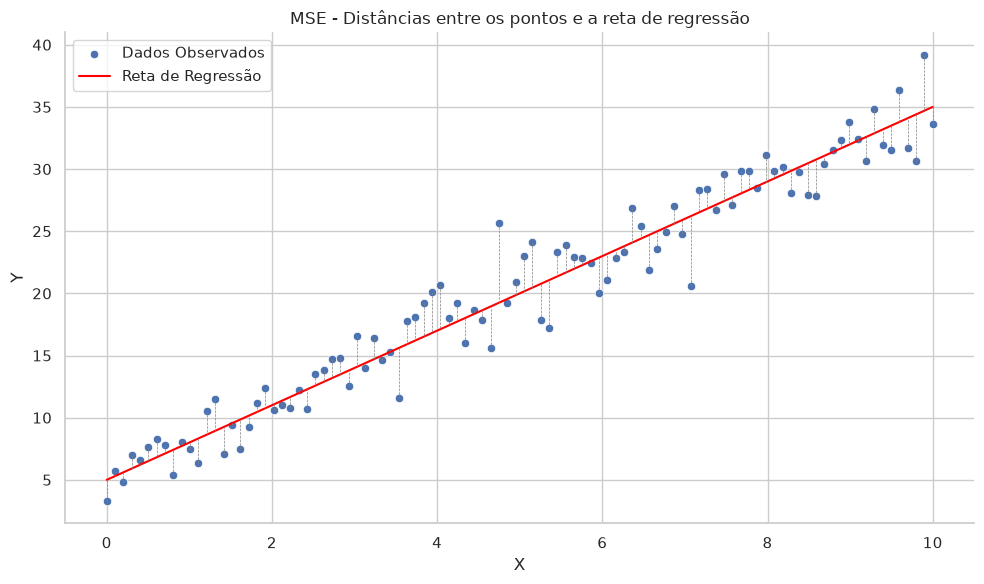

In [11]:
# Gráfico representando a MSE 
x = np.linspace(0, 10, 100)
y = 3 * x + 5 + np.random.normal(0, 2, size=x.shape)  # y = 3x + 5 + ruído gaussiano

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x, y=y, marker='o', label='Dados Observados')
# Reta de regressão
y_pred = 3 * x + 5
plt.plot(x, y_pred, color='red', label='Reta de Regressão')

# Mostrar as distâncias (resíduos) entre os pontos e a reta de regressão
for i in range(len(x)):
    plt.plot([x[i], x[i]], [y[i], y_pred[i]], color='gray', linestyle='--', linewidth=0.5)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('MSE - Distâncias entre os pontos e a reta de regressão')
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

Nesse exemplo do gráfico acima, temos uma reta de regressão e as linhas verticais representam o **erro** do modelo: a distância entre o valor previsto do valor real para aquele valor de x. É este erro que será elevado ao quadrado.

Agora conhecemos a principal Função de Custo utilizada na Regressão Linear, e sabemos que precisamos *minimizar* ou diminuir essa função ao máximo possível, uma dúvida pode ter surgido: *como, de fato, minimizar essa função* para treinar o modelo?

# Ideia de Derivada

Um conceito importantíssimo para aprender como os modelos de Aprendizado de Máquina "aprendem" é o conceito do Cálculo Diferencial de Derivada, e seu equivalente no Gradiente. Um curso mais aprofundado de Cálculo será necessário para aprender a extensão deste tópico vasto; aqui, focaremos apenas em uma abordagem intuitiva.

De modo geral, a derivada mede a **taxa de variação** de uma função em um ponto. Isto é, para uma função qualquer, a derivada da função em um ponto vai medir *o quanto a função está variando EXATAMENTE naquele ponto*. Pense em uma montanha, por exemplo: se você estar perto do topo da montanha, mas ainda não chegou na montanha, é provável que a derivada seja um número positivo alto, indicando que a montanha está ganhando altura rapidamente naquela região. Já no topo ou no vale de uma montanha, a derivada vai tender a zero, pois o terreno se assenta e para de variar com frequência, não ganhando e nem perdendo altura significativa.

Em um gráfico, a derivada pode ser entendida como a *inclinação da reta tangente*: se a derivada é positiva, a função cresce; se é negativa, a função diminui; e se é zero, chegamos a um ponto onde a função deixa de subir ou descer naquele instante. A intuição da derivada como inclinação da reta tangente ao ponto já é o suficiente para os propósitos do curso, mas, seguimos com uma descrição um pouco mais matemática:

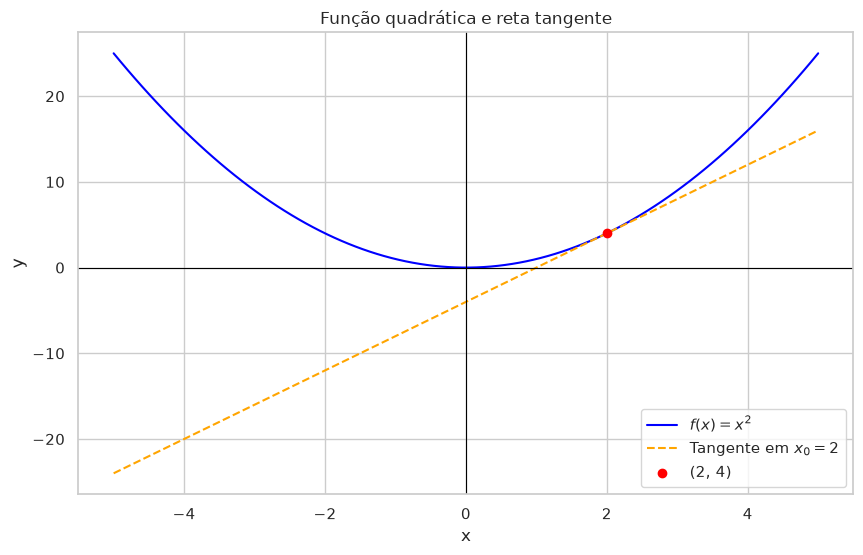

Derivada no ponto x0 = 4


In [17]:
# Fazer o gráfico de uma função x² com a reta tangente no ponto simbolizando a derivada no ponto
plt.figure(figsize=(10, 6))

# Função
x = np.linspace(-5, 5, 100)
y = x**2

# Escolher o ponto de tangência
x0 = 2
y0 = x0**2

# Derivada no ponto: inclinação da reta tangente
derivada = 2 * x0

# Equação da reta tangente
y_tangente = y0 + derivada * (x - x0)

# Gráficos
plt.plot(x, y, label=r'$f(x)=x^2$', color='blue')
plt.plot(x, y_tangente, label=rf'Tangente em $x_0={x0}$', 
         color='orange', linestyle='--')

# Destacar o ponto de tangência
plt.scatter(x0, y0, color='red', zorder=3, label=f'({x0}, {y0})')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Função quadrática e reta tangente')
plt.grid(True)
plt.legend()
plt.show()
print("Derivada no ponto x0 =", derivada)

### A Derivada, intuição matemática

Não conseguimos descrever facilmente, matematicamente, a tangente a um ponto na função, mas podemos aproximá-la por meio de uma **reta secante**, da qual conseguimos calcular.  
A reta secante escolhida passará por dois pontos da curva da função. Para uma função $f(x)$, escolhendo um ponto $x$ e outro ponto $x + h$, formamos um triângulo retângulo:

- $\Delta x = h$ é o deslocamento horizontal;
- $\Delta y = f(x+h) - f(x)$ é o deslocamento vertical;
- $\frac{\Delta y}{\Delta x}$ é a inclinação da **secante**.

Assim, a inclinação média da reta secante entre os dois pontos é:

$$\frac{f(x + h) - f(x)}{h}$$

A inclinação dessa reta secante **não é a derivada** da função no ponto x, porém, a medida em que os valores de $h$ ficam menores e menores, o segundo ponto $(x +h)$ fica mais e mais próximo do primeiro ponto, fazendo a reta secante TENDER a reta tangente. A animação interativa abaixo mostra exatamente esse comportamento ocorrendo.

Assim, no *limite* (a medida que os valores de $h$ se aproximam de zero, mas nunca cheguem a valer zero), a reta secante converge cada vez mais para a tangente no ponto, e a inclinação dessa reta tangente é a derivada:

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

Por exemplo, para a função $f(x) = x^2$, temos:

$$f'(x) = 2x$$

Que é a **função derivada** de $f(x)$.

In [ ]:
# Animar a secante se aproximando da tangente em f(x) = x^2


funcao = lambda valor: valor ** 2
ponto_x = 2
x_funcao = np.linspace(0.5, 3.5, 300)
y_funcao = funcao(x_funcao)
hs_animacao = np.geomspace(2.0, 0.03, 70)
inclinacao_tangente = 2 * ponto_x

fig, eixo = plt.subplots(figsize=(10, 6))
eixo.plot(x_funcao, y_funcao, label='$f(x) = x^2$')
x_tangente = np.linspace(ponto_x - 1, ponto_x + 1, 100)
y_tangente = funcao(ponto_x) + inclinacao_tangente * (x_tangente - ponto_x)
eixo.plot(x_tangente, y_tangente, color='red', linestyle='--', alpha=0.6, label='Tangente no limite')

linha_secante, = eixo.plot([], [], color='orange', linestyle='--', label='Secante')
pontos_secante, = eixo.plot([], [], 'o', color='red', zorder=3)
linha_horizontal, = eixo.plot([], [], color='green', linewidth=2)
linha_vertical, = eixo.plot([], [], color='green', linewidth=2)
texto_delta_x = eixo.text(0, 0, '', color='green', ha='center')
texto_delta_y = eixo.text(0, 0, '', color='green')
texto_inclinacao = eixo.text(
    0.03,
    0.95,
    '',
    transform=eixo.transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=3)
)

eixo.set_xlim(0.5, 3.5)
eixo.set_ylim(-1, 13)
eixo.set_xlabel('x')
eixo.set_ylabel('f(x)')
eixo.set_title('A secante se transformando na tangente')
eixo.legend(loc='upper right')
sns.despine()


def atualizar_derivada(frame):
    passo = hs_animacao[frame]
    y_inicial = funcao(ponto_x)
    y_final = funcao(ponto_x + passo)
    inclinacao = (y_final - y_inicial) / passo
    x_secante = np.array([ponto_x - 0.2, ponto_x + passo + 0.2])
    y_secante = y_inicial + inclinacao * (x_secante - ponto_x)

    linha_secante.set_data(x_secante, y_secante)
    pontos_secante.set_data([ponto_x, ponto_x + passo], [y_inicial, y_final])
    linha_horizontal.set_data([ponto_x, ponto_x + passo], [y_inicial, y_inicial])
    linha_vertical.set_data([ponto_x + passo, ponto_x + passo], [y_inicial, y_final])
    texto_delta_x.set_position((ponto_x + passo / 2, y_inicial - 0.7))
    texto_delta_x.set_text(f'delta x = {passo:.2f}')
    texto_delta_y.set_position((ponto_x + passo + 0.04, (y_inicial + y_final) / 2))
    texto_delta_y.set_text(f'delta y = {y_final - y_inicial:.2f}')
    texto_inclinacao.set_text(f'h = {passo:.3f}   inclinacao = {inclinacao:.3f}')
    return (linha_secante, pontos_secante, linha_horizontal, linha_vertical,
            texto_delta_x, texto_delta_y, texto_inclinacao)


animacao_derivada = FuncAnimation(
    fig, atualizar_derivada, frames=len(hs_animacao), interval=80, blit=False
)
plt.close(fig)
HTML(animacao_derivada.to_jshtml())

O destaque aqui, que nos interessa para o aprendizado de máquina, é particularmente nas sitauções onde a **derivada é zero**, pois isso significa que, na região ao redor daquele ponto, a função não muda. Isso **pode** indicar um *mínimo global*, um ponto ande a função está assumindo o menor valor possível (ou um dos menores valores possíveis), que é exatamente a intuição por trás de "minimizar a função de custo".

# Noção Intuitiva do Método do Gradiente

A derivada nos mostra o quanto a função está variando em um ponto. Porém, para funções com múltiplas variáveis, como é o caso da nossa *função de custo* (que pode variar tanto em $a$ quanto em $b$, se lembra?), a derivada sozinha é insuficiente, pois essas funções não mais possuem apenas dois eixos, mas sim, 3 eixos ou mais, tornando a derivada convencional *incompleta*.
Pense, por exemplo, na função: $$z = x^2 + y^2$$
Essa é uma função que recebe *duas variáveis de entrada*, o que significa que precisa de um gráfico em *3 dimensões* para ser representada, com o eixo vertical $z$ sendo o responsável por mostrar o valor da função naquele ponto $(x, y)$.

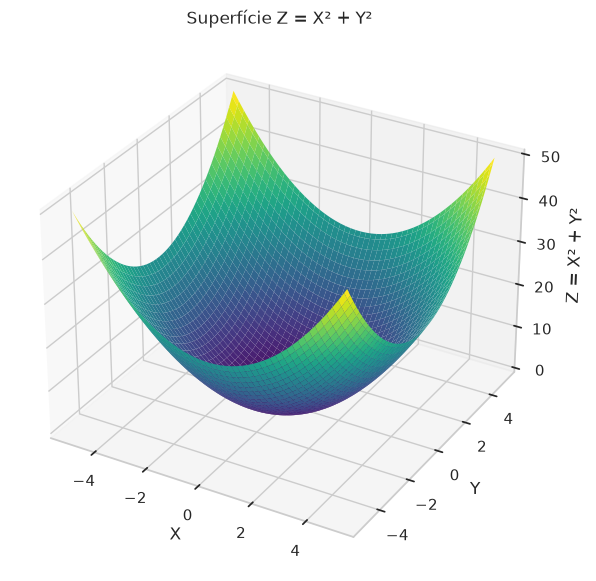

In [19]:
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

# Criar a grade 2D
X, Y = np.meshgrid(x, y)

# Calcular Z = x² + y²
Z = X**2 + Y**2

# Criar o gráfico 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z = X² + Y²")
ax.set_title("Superfície Z = X² + Y²")

plt.show()


Neste cenário, a derivada sozinha não bastaria, pois ela estaria medindo apenas a derivada **de um eixo específico** (como o eixo x, por exemplo). Para corretamente termos uma noção mais apropriada de *o quanto a função está variando naquele ponto*, precisamos avaliar uma espécie de derivada pra cada eixo de entrada da função. É aí que entram as **derivadas parciais**.

Uma derivada parcial é, essencialmente, a *derivada de uma função de duas ou mais variáveis em relação a uma das variáveis, mantendo as outras constantes*. Assim, por exemplo, a derivada parcial de $x^2 + y^2 = z$ *em relação a x* seria a derivada da função tratando $y$ como uma constante, que ficaria $2x$. Da mesma forma, a derivada parcial de $x^2 + y^2 = z$ *em relação a y* seria tratar $x$ como uma constante e resultaria em $2y$.

O chamado **vetor gradiente** é a junção de todas as derivadas parciais. No caso acima:

$$\nabla f = (2x, 2y)$$

O Gradiente é um **vetor** que aponta para a direção onde a função estará *crescendo* na região daquele ponto $(x, y)$, ou seja, se nós seguirmos na direção em que o Gradiente aponta, estaremos buscando achar um possível valor máximo da função. Se nós fizermos *o caminho contrário do Gradiente*, então, estaremos indo para a direção onde a função *diminui*, o que pode nos ajudar a encontrar o mínimo global da função, que é o que queremos na função de custo.

Assim sendo, o *método do Gradiente Descente* se resume em, basicamente, iniciar a Função de Custo com valores aleatórios ou padrão para as duas variáveis de entrada, encontrar o Gradiente daquele ponto (que apontará para onde a função cresce mais perto daquele ponto), seguir **um pequeno passo na direção contrária ao vetor Gradiente**, e repetir para esse novo ponto em que paramos após o pequeno passo. Esse é o método do Gradiente Descente resumido. Ele irá sempre fazer com que encontramos gradientes na função, que no caso é a função de custo, que minimizam o valor de $z$ da função progressivamente, até encontrarmos um ponto de mínimo onde o gradiente é zero ou muito baixo, o que pode indicar que encontramos o mínimo da função, como gostaríamos (minimizando os erros, portanto). 

### Gradiente Descente, intuição matemática.

Como queremos **diminuir** o erro, caminhamos na direção contrária ao gradiente. Em uma única dimensão, a regra é:

$$w_{novo} = w_{atual} - \alpha \frac{dJ}{dw}$$

Considere, por exemplo, a função $J(w) = w^2$. Se começarmos em $w = 2.5$, então:

$$J(2.5) = 6.25 \quad \text{e} \quad J'(2.5) = 5$$

Com $\alpha = 0.2$, o próximo passo será:

$$w_{novo} = 2.5 - 0.2 \times 5 = 1.5$$

O novo ponto está mais perto do mínimo, que acontece em $w = 0$. Repetindo a operação, caminhamos gradualmente para o menor custo. Se a taxa for muito grande, podemos passar pelo mínimo; se for muito pequena, o treinamento pode ser demorado.

In [ ]:
# Animar os passos do gradiente descendente em J(w) = w^2
funcao_custo = lambda valor: valor ** 2
pontos = np.linspace(-3, 3, 300)
taxa_aprendizado = 0.2
ponto_atual = 2.5
historico = [ponto_atual]
custos_gradiente = [funcao_custo(ponto_atual)]

for _ in range(14):
    derivada = 2 * ponto_atual
    ponto_atual = ponto_atual - taxa_aprendizado * derivada
    historico.append(ponto_atual)
    custos_gradiente.append(funcao_custo(ponto_atual))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].plot(pontos, funcao_custo(pontos), label='$J(w) = w^2$')
trajetoria, = eixos[0].plot([], [], 'o--', color='red', label='Caminho do gradiente')
ponto_gradiente, = eixos[0].plot([], [], 'o', color='blue', markersize=9, zorder=3)
texto_passo = eixos[0].text(0.03, 0.92, '', transform=eixos[0].transAxes)
eixos[0].set_xlabel('Parametro w')
eixos[0].set_ylabel('Funcao de custo J(w)')
eixos[0].set_title('O ponto caminhando ate o minimo')
eixos[0].legend()

evolucao_custo, = eixos[1].plot([], [], 'o-', color='green')
eixos[1].set_xlim(0, len(custos_gradiente) - 1)
eixos[1].set_ylim(0, custos_gradiente[0] * 1.05)
eixos[1].set_xlabel('Passo')
eixos[1].set_ylabel('J(w)')
eixos[1].set_title('O custo diminuindo a cada atualizacao')
eixos[1].set_xticks(range(0, len(custos_gradiente), 2))

sns.despine()


def atualizar_gradiente(frame):
    pontos_atuais = np.array(historico[:frame + 1])
    custos_atuais = np.array(custos_gradiente[:frame + 1])
    trajetoria.set_data(pontos_atuais, custos_atuais)
    ponto_gradiente.set_data([historico[frame]], [custos_gradiente[frame]])
    evolucao_custo.set_data(range(frame + 1), custos_atuais)
    texto_passo.set_text(
        f'passo {frame}: w = {historico[frame]:.3f}\nJ(w) = {custos_gradiente[frame]:.4f}'
    )
    return trajetoria, ponto_gradiente, evolucao_custo, texto_passo


animacao_gradiente = FuncAnimation(
    fig, atualizar_gradiente, frames=len(historico), interval=350, blit=False
)
plt.close(fig)
HTML(animacao_gradiente.to_jshtml())